<a href="https://colab.research.google.com/github/codeKrantz/Iowa-State-AI-2010/blob/main/CNN_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Data Loading

In [1]:
import os
import shutil
import zipfile
import tensorflow as tf
from PIL import Image


def data_loader(zip_path="/content/drive/MyDrive/AI 2010 Data Set/archive.zip",
                extract_to="/content/data",
                img_size=(128, 128),
                batch_size=32,
                val_split=0.2,
                seed=42,
                keep_classes=None):
    """Load the electronic-components dataset (archive.zip -> images/<class>/...).

    keep_classes: optional list of class folder names to use. Other class
                  folders are moved to <extract_to>/excluded (not deleted), and
                  are moved back automatically if you later include them again.

    Returns train_ds, val_ds, class_names. Images are scaled to [0, 1];
    labels are integers (use sparse_categorical_crossentropy).
    """
    # Unzip to Colab's local disk once (much faster than reading from Drive)
    data_dir = os.path.join(extract_to, "images")
    if not os.path.isdir(data_dir):
        with zipfile.ZipFile(zip_path) as zf:
            zf.extractall(extract_to)

    # The zip contains a duplicate copy of the whole dataset at images/images/.
    # Keras would treat it as a 38th class called "images", so delete it.
    nested = os.path.join(data_dir, "images")
    if os.path.isdir(nested):
        shutil.rmtree(nested)

    # Optionally restrict to a subset of classes
    excluded_dir = os.path.join(extract_to, "excluded")
    os.makedirs(excluded_dir, exist_ok=True)
    for cls in os.listdir(excluded_dir):            # restore everything first
        shutil.move(os.path.join(excluded_dir, cls), os.path.join(data_dir, cls))
    if keep_classes is not None:
        all_classes = sorted(d for d in os.listdir(data_dir)
                             if os.path.isdir(os.path.join(data_dir, d)))
        missing = set(keep_classes) - set(all_classes)
        if missing:
            raise ValueError(f"Unknown class name(s): {sorted(missing)}")
        for cls in all_classes:
            if cls not in keep_classes:
                shutil.move(os.path.join(data_dir, cls), os.path.join(excluded_dir, cls))

    # Remove files TensorFlow can't decode so training doesn't crash
    for root, _, files in os.walk(data_dir):
        for f in files:
            path = os.path.join(root, f)
            try:
                with Image.open(path) as img:
                    fmt = img.format
                    img.verify()
                if fmt not in ("JPEG", "PNG", "BMP", "GIF"):
                    os.remove(path)
            except Exception:
                os.remove(path)

    # Each subfolder of images/ is a class
    train_ds, val_ds = tf.keras.utils.image_dataset_from_directory(
        data_dir,
        validation_split=val_split,
        subset="both",
        seed=seed,
        image_size=img_size,
        batch_size=batch_size,
        label_mode="int",
    )
    class_names = train_ds.class_names
    print(f"{len(class_names)} classes: {class_names}")

    # Preprocess: scale pixels to [0, 1]; cache + prefetch for speed
    normalize = tf.keras.layers.Rescaling(1.0 / 255)
    AUTOTUNE = tf.data.AUTOTUNE
    train_ds = (train_ds.map(lambda x, y: (normalize(x), y), num_parallel_calls=AUTOTUNE)
                        .cache()
                        .shuffle(100, seed=seed)
                        .prefetch(AUTOTUNE))
    # cache() fixes the validation order, so predictions line up with labels later
    val_ds = (val_ds.map(lambda x, y: (normalize(x), y), num_parallel_calls=AUTOTUNE)
                    .cache()
                    .prefetch(AUTOTUNE))

    return train_ds, val_ds, class_names

In [2]:
from google.colab import drive
drive.mount('/content/drive')
#There were too many classes, this reduces that number to improve accuracy
keep = ["LED", "Electrolytic-capacitor", "Integrated-micro-circuit", "potentiometer",
        "heat-sink", "electric-relay", "filament", "solenoid",
        "step-down-transformer", "junction-transistor", "jumper-cable", "cartridge-fuse"]

train_ds, val_ds, class_names = data_loader(keep_classes=keep)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Found 4751 files belonging to 12 classes.
Using 3801 files for training.
Using 950 files for validation.
12 classes: ['Electrolytic-capacitor', 'Integrated-micro-circuit', 'LED', 'cartridge-fuse', 'electric-relay', 'filament', 'heat-sink', 'jumper-cable', 'junction-transistor', 'potentiometer', 'solenoid', 'step-down-transformer']


#Image Visualization

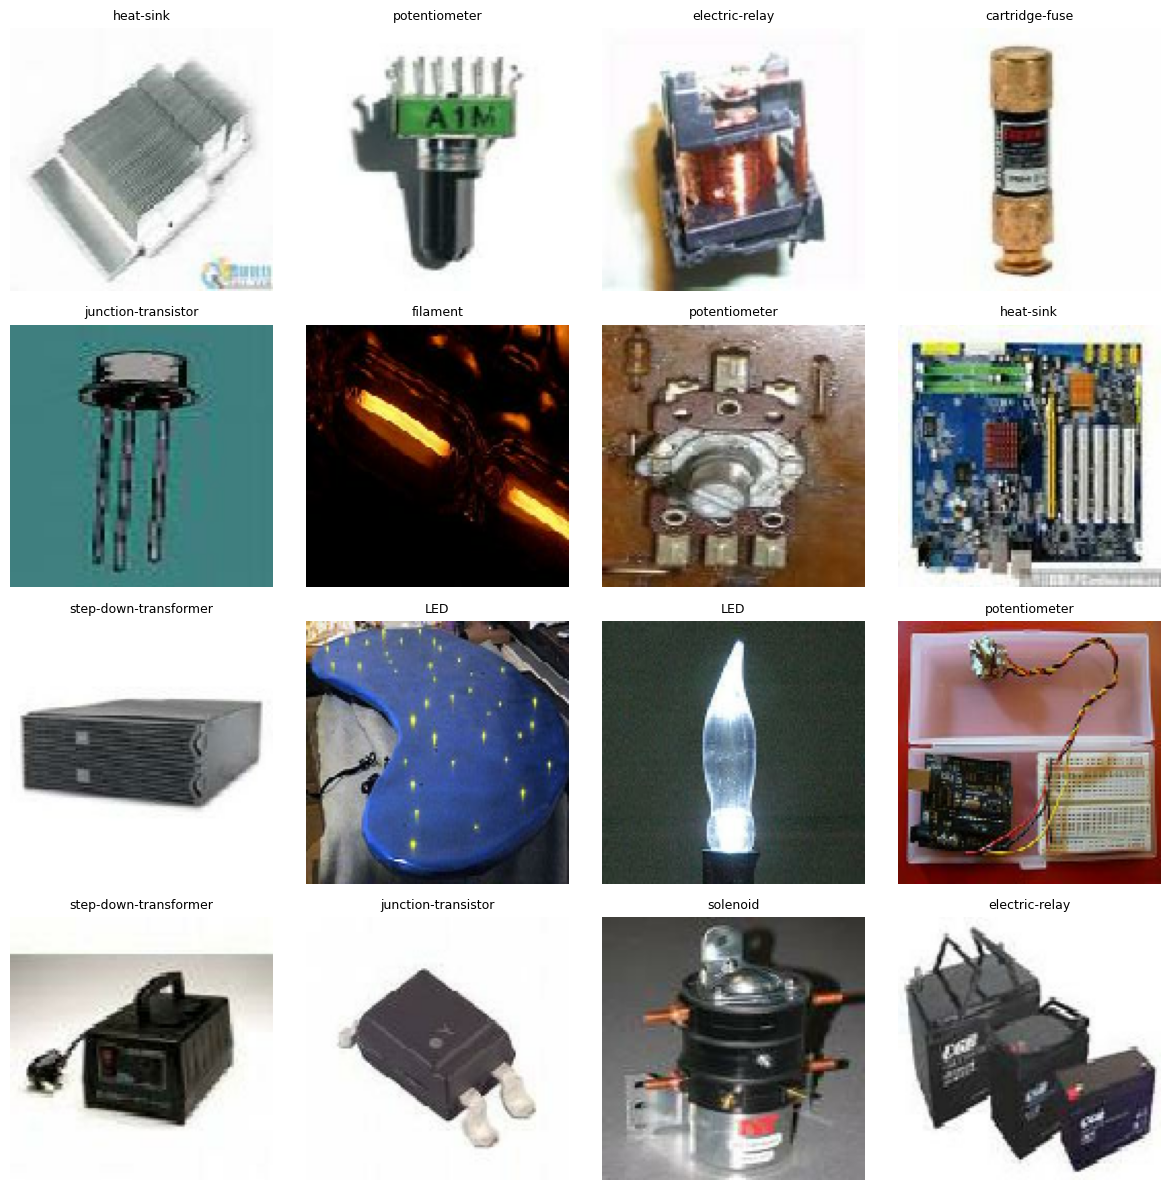

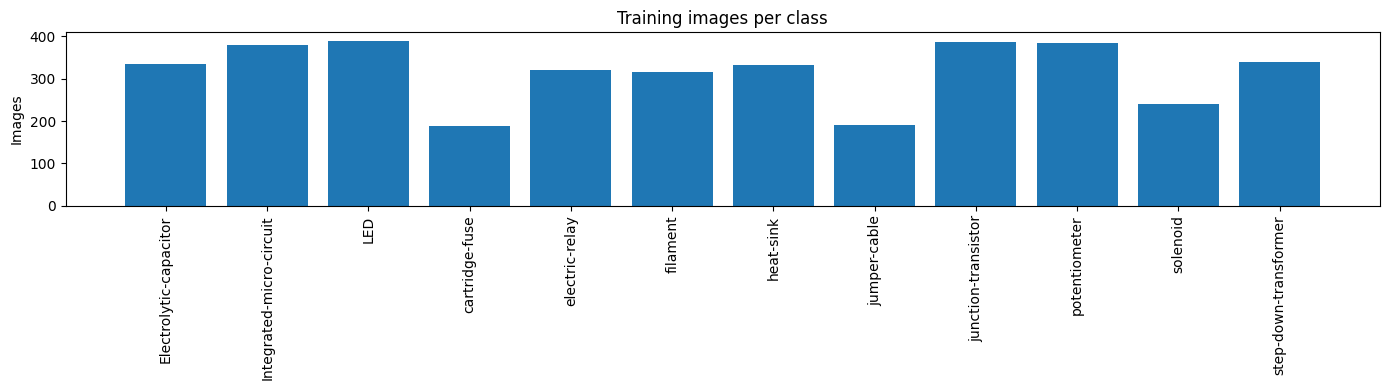

min 188, max 390, mean 317


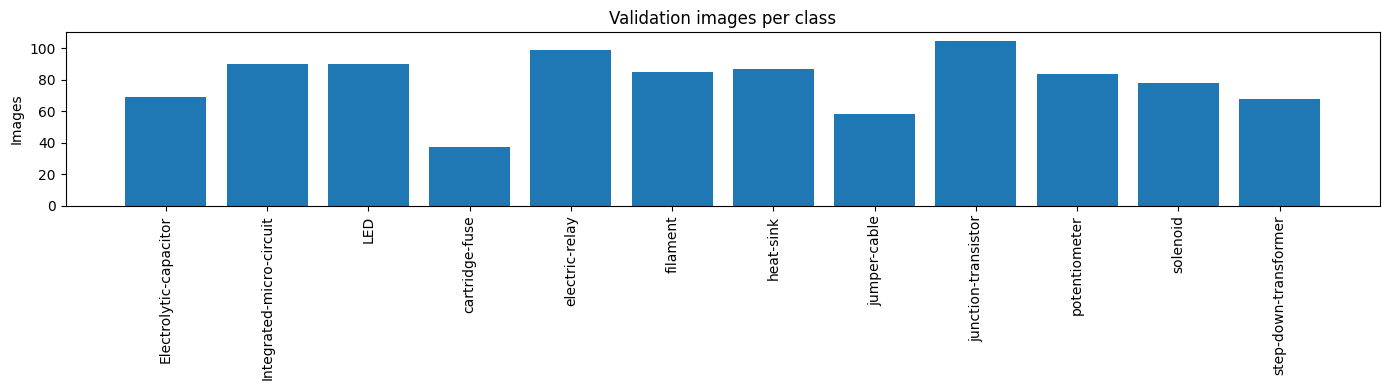

min 37, max 105, mean 79


In [3]:
import matplotlib.pyplot as plt
import numpy as np

def show_samples(ds, class_names, n=16):
    """Show a grid of n images from one batch with their class labels."""
    images, labels = next(iter(ds))
    n = min(n, len(images))
    cols = 4
    rows = int(np.ceil(n / cols))
    plt.figure(figsize=(12, 3 * rows))
    for i in range(n):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(images[i].numpy())          # already scaled to [0, 1]
        plt.title(class_names[int(labels[i])], fontsize=9)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

def plot_class_distribution(ds, class_names, title):
    """Bar chart of how many images each class has in a dataset."""
    counts = np.zeros(len(class_names), dtype=int)
    for _, labels in ds:
        counts += np.bincount(labels.numpy(), minlength=len(class_names))
    plt.figure(figsize=(14, 4))
    plt.bar(class_names, counts)
    plt.xticks(rotation=90)
    plt.ylabel("Images")
    plt.title(title)
    plt.tight_layout()
    plt.show()
    print(f"min {counts.min()}, max {counts.max()}, mean {counts.mean():.0f}")

show_samples(train_ds, class_names)
plot_class_distribution(train_ds, class_names, "Training images per class")
plot_class_distribution(val_ds, class_names, "Validation images per class")

#CNN Model

In [4]:
import tensorflow as tf
from tensorflow.keras import layers, models


def build_model(num_classes, input_shape=(128, 128, 3), learning_rate=1e-3):
    """Create and compile a simple CNN for image classification.

    Args:
        num_classes  : number of output classes (len(class_names))
        input_shape  : image shape from data_loader (default 128x128 RGB)
        learning_rate: Adam learning rate

    Inputs are expected to already be scaled to [0, 1] (data_loader does this).
    Labels are integers, so the loss is sparse_categorical_crossentropy.
    """
    model = models.Sequential([
        layers.Input(shape=input_shape),

        # Data augmentation: only active during training, ignored at evaluation
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),

        # Block 1
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        # Block 2
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        # Block 3
        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        # Block 4
        layers.Conv2D(256, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        # Classifier head
        layers.GlobalAveragePooling2D(),   # far fewer parameters than Flatten
        layers.Dropout(0.5),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation="softmax"),
    ], name="simple_cnn")

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

In [5]:
model = build_model(num_classes=len(class_names))
model.summary()

Model: "simple_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 12)             │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 424,780 (1.62 MB)

 Trainable params: 423,820 (1.62 MB)

 Non-trainable params: 960 (3.75 KB)

# Trainer

In [6]:
import numpy as np
import tensorflow as tf


def trainer(model, train_ds, val_ds, num_classes,
            epochs=30, learning_rate=1e-3, use_class_weights=True):
    """Compile and train the CNN.

    Args:
        model            : model from build_model()
        train_ds, val_ds : datasets from data_loader()
        num_classes      : len(class_names)
        epochs           : max epochs (early stopping usually ends sooner)
        learning_rate    : starting Adam learning rate
        use_class_weights: weight rare classes more, since class sizes are uneven

    Returns:
        history : Keras History object (pass to visualize_training)
    """
    # 1) Compile: Adam optimizer + sparse categorical cross-entropy (integer labels)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    # 2) Class weights: rare classes count more in the loss, so the model
    #    doesn't just learn to predict the big classes
    class_weight = None
    if use_class_weights:
        counts = np.zeros(num_classes, dtype=np.int64)
        for _, labels in train_ds:
            counts += np.bincount(labels.numpy(), minlength=num_classes)
        weights = counts.sum() / (num_classes * np.maximum(counts, 1))
        class_weight = {i: float(w) for i, w in enumerate(weights)}
        print(f"Class weights range: {weights.min():.2f} - {weights.max():.2f}")

    # 3) Callbacks
    callbacks = [
        # Stop when validation loss stops improving; keep the best epoch's weights
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=6, restore_best_weights=True, verbose=1),
        # Halve the learning rate when validation loss plateaus
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1),
    ]

    # 4) Train
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs,
        class_weight=class_weight,
        callbacks=callbacks,
        verbose=1,
    )
    return history

In [7]:
model = build_model(num_classes=len(class_names))
history = trainer(model, train_ds, val_ds, num_classes=len(class_names), epochs=50)

Class weights range: 0.81 - 1.68
Epoch 1/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 16s 58ms/step - accuracy: 0.1771 - loss: 2.5013 - val_accuracy: 0.0895 - val_loss: 4.0608 - learning_rate: 0.0010
Epoch 2/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - accuracy: 0.2341 - loss: 2.2015 - val_accuracy: 0.1042 - val_loss: 3.9229 - learning_rate: 0.0010
Epoch 3/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - accuracy: 0.2447 - loss: 2.1421 - val_accuracy: 0.1137 - val_loss: 3.9540 - learning_rate: 0.0010
Epoch 4/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 10s 44ms/step - accuracy: 0.2626 - loss: 2.0763 - val_accuracy: 0.1779 - val_loss: 2.6768 - learning_rate: 0.0010
Epoch 5/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 6s 47ms/step - accuracy: 0.2805 - loss: 2.0437 - val_accuracy: 0.2811 - val_loss: 2.0601 - learning_rate: 0.0010
Epoch 6/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - accuracy: 0.2936 - loss: 2.0114 - val_accuracy: 0.3116 - val_loss: 1.9888 - learning_rate: 0.0010
Epoch 7/50
119/119 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms

# Evaluation

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)


def visualize_training(history):
    """Plot training vs. validation accuracy and loss over epochs."""
    h = history.history
    epochs = range(1, len(h["loss"]) + 1)
    best = int(np.argmin(h["val_loss"])) + 1   # epoch whose weights were kept

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    ax1.plot(epochs, h["accuracy"], label="Training")
    ax1.plot(epochs, h["val_accuracy"], label="Validation")
    ax1.axvline(best, color="gray", linestyle="--", label=f"Best epoch ({best})")
    ax1.set_title("Accuracy over epochs")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Accuracy")
    ax1.legend()
    ax1.grid(alpha=0.3)

    ax2.plot(epochs, h["loss"], label="Training")
    ax2.plot(epochs, h["val_loss"], label="Validation")
    ax2.axvline(best, color="gray", linestyle="--", label=f"Best epoch ({best})")
    ax2.set_title("Loss over epochs")
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("Loss")
    ax2.legend()
    ax2.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    print(f"Best epoch: {best} | "
          f"train acc {h['accuracy'][best-1]:.3f}, val acc {h['val_accuracy'][best-1]:.3f} | "
          f"train loss {h['loss'][best-1]:.3f}, val loss {h['val_loss'][best-1]:.3f}")


def evaluate_model(model, val_ds, class_names, show_confusion_matrix=True):
    """Compute accuracy, precision, recall and F1 on the validation set.

    Returns a dict with the overall metrics plus y_true / y_pred arrays
    (reuse them in visualize_misclassifications).
    """
    # Predict batch by batch so each prediction stays paired with its label
    y_true, y_pred = [], []
    for images, labels in val_ds:
        probs = model.predict(images, verbose=0)
        y_pred.append(np.argmax(probs, axis=1))
        y_true.append(labels.numpy())
    y_true = np.concatenate(y_true)
    y_pred = np.concatenate(y_pred)

    # Overall metrics
    acc = accuracy_score(y_true, y_pred)
    p_mac, r_mac, f_mac, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0)
    p_w, r_w, f_w, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0)

    print(f"Validation images: {len(y_true)}")
    print(f"Accuracy:            {acc:.4f}")
    print(f"Precision (macro):   {p_mac:.4f}   (weighted: {p_w:.4f})")
    print(f"Recall    (macro):   {r_mac:.4f}   (weighted: {r_w:.4f})")
    print(f"F1-score  (macro):   {f_mac:.4f}   (weighted: {f_w:.4f})")
    print("\nMacro = every class counts equally; weighted = by class size.\n")

    # Per-class breakdown
    print(classification_report(y_true, y_pred, labels=range(len(class_names)),
                                target_names=class_names, digits=3, zero_division=0))

    # Confusion matrix (row-normalized so small classes are readable)
    if show_confusion_matrix:
        cm = confusion_matrix(y_true, y_pred, labels=range(len(class_names)))
        cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
        plt.figure(figsize=(14, 12))
        plt.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
        plt.colorbar(label="Fraction of true class")
        plt.xticks(range(len(class_names)), class_names, rotation=90, fontsize=8)
        plt.yticks(range(len(class_names)), class_names, fontsize=8)
        plt.xlabel("Predicted label")
        plt.ylabel("True label")
        plt.title("Confusion matrix (validation, row-normalized)")
        plt.tight_layout()
        plt.show()

    return {
        "accuracy": acc,
        "precision_macro": p_mac, "recall_macro": r_mac, "f1_macro": f_mac,
        "precision_weighted": p_w, "recall_weighted": r_w, "f1_weighted": f_w,
        "y_true": y_true, "y_pred": y_pred,
    }

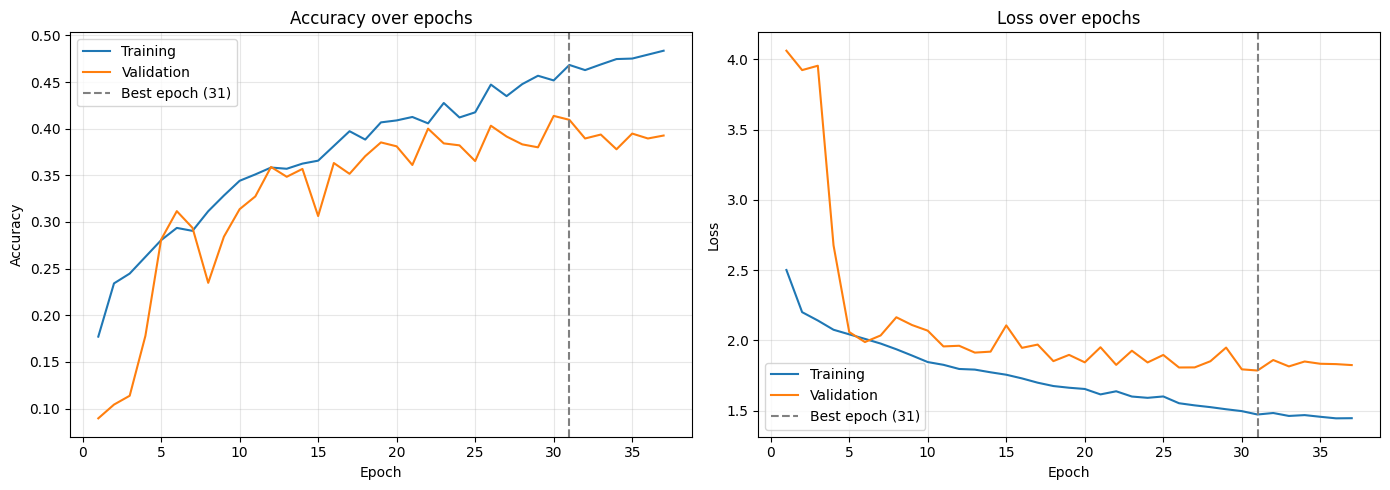

Best epoch: 31 | train acc 0.468, val acc 0.409 | train loss 1.474, val loss 1.786
Validation images: 950
Accuracy:            0.4095
Precision (macro):   0.4064   (weighted: 0.4045)
Recall    (macro):   0.4215   (weighted: 0.4095)
F1-score  (macro):   0.3880   (weighted: 0.3788)

Macro = every class counts equally; weighted = by class size.

                          precision    recall  f1-score   support

  Electrolytic-capacitor      0.391     0.130     0.196        69
Integrated-micro-circuit      0.435     0.600     0.505        90
                     LED      0.450     0.556     0.498        90
          cartridge-fuse      0.415     0.459     0.436        37
          electric-relay      0.356     0.212     0.266        99
                filament      0.551     0.765     0.640        85
               heat-sink      0.325     0.586     0.418        87
            jumper-cable      0.500     0.672     0.574        58
     junction-transistor      0.400     0.095     0.154     

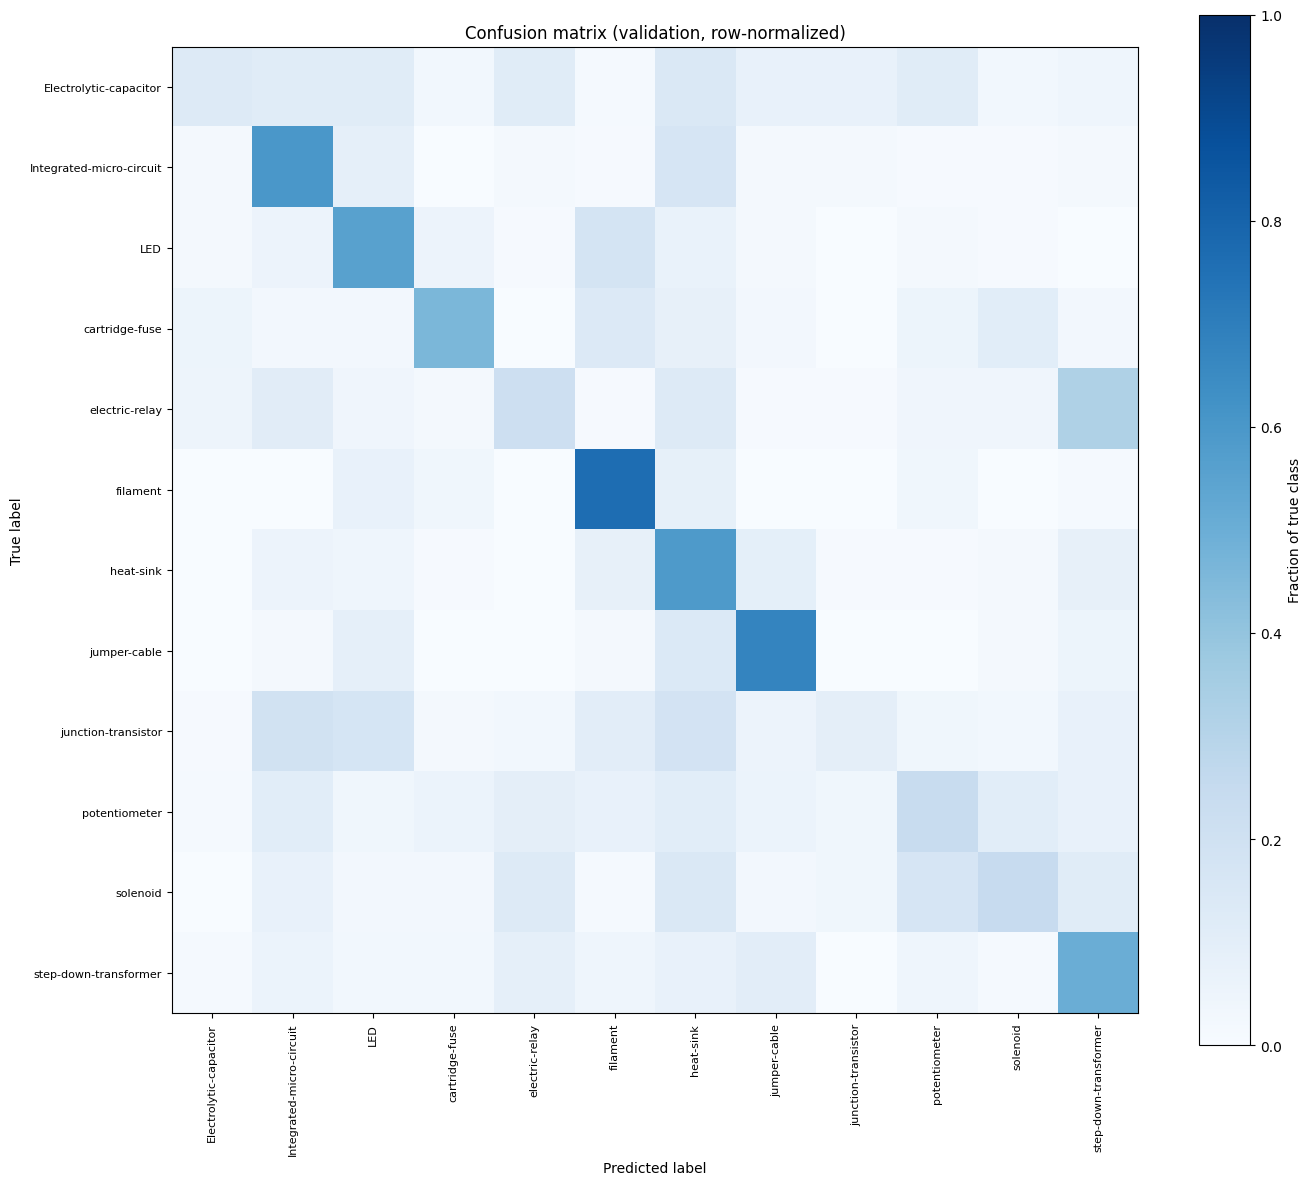

In [9]:
visualize_training(history)
results = evaluate_model(model, val_ds, class_names)

#Viewing Prediction Errors

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter


def visualize_misclassifications(model, val_ds, class_names, n=16, cols=4,
                                 most_confident=True):
    """Display validation images the model got wrong, with true and predicted labels.

    Args:
        model          : trained model
        val_ds         : validation dataset from data_loader()
        class_names    : list of class names
        n              : how many misclassified images to show
        cols           : images per row
        most_confident : True = show the mistakes the model was MOST sure about
                         (usually the most informative); False = first n found
    """
    wrong_imgs, wrong_true, wrong_pred, wrong_conf = [], [], [], []
    total = 0

    # Predict batch by batch so each image stays paired with its label
    for images, labels in val_ds:
        probs = model.predict(images, verbose=0)
        preds = np.argmax(probs, axis=1)
        labels = labels.numpy()
        total += len(labels)

        mask = preds != labels
        wrong_imgs.extend(images.numpy()[mask])
        wrong_true.extend(labels[mask])
        wrong_pred.extend(preds[mask])
        wrong_conf.extend(probs[mask, preds[mask]])

    n_wrong = len(wrong_true)
    print(f"Misclassified {n_wrong} of {total} validation images "
          f"({n_wrong / total:.1%})")
    if n_wrong == 0:
        return

    # Most common confusions (true -> predicted)
    pairs = Counter(zip(wrong_true, wrong_pred)).most_common(5)
    print("\nMost common mistakes (true -> predicted):")
    for (t, p), count in pairs:
        print(f"  {class_names[t]:<25s} -> {class_names[p]:<25s} {count}")

    # Choose which mistakes to show
    order = (np.argsort(wrong_conf)[::-1] if most_confident
             else np.arange(n_wrong))[:n]

    rows = int(np.ceil(len(order) / cols))
    plt.figure(figsize=(cols * 3.5, rows * 3.8))
    for i, idx in enumerate(order):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(wrong_imgs[idx])            # already scaled to [0, 1]
        plt.title(f"True: {class_names[wrong_true[idx]]}\n"
                  f"Pred: {class_names[wrong_pred[idx]]} ({wrong_conf[idx]:.0%})",
                  fontsize=9, color="red")
        plt.axis("off")
    title = "Most confident misclassifications" if most_confident else "Misclassified images"
    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

Misclassified 561 of 950 validation images (59.1%)

Most common mistakes (true -> predicted):
  electric-relay            -> step-down-transformer     32
  junction-transistor       -> Integrated-micro-circuit  20
  junction-transistor       -> heat-sink                 19
  junction-transistor       -> LED                       18
  LED                       -> filament                  16


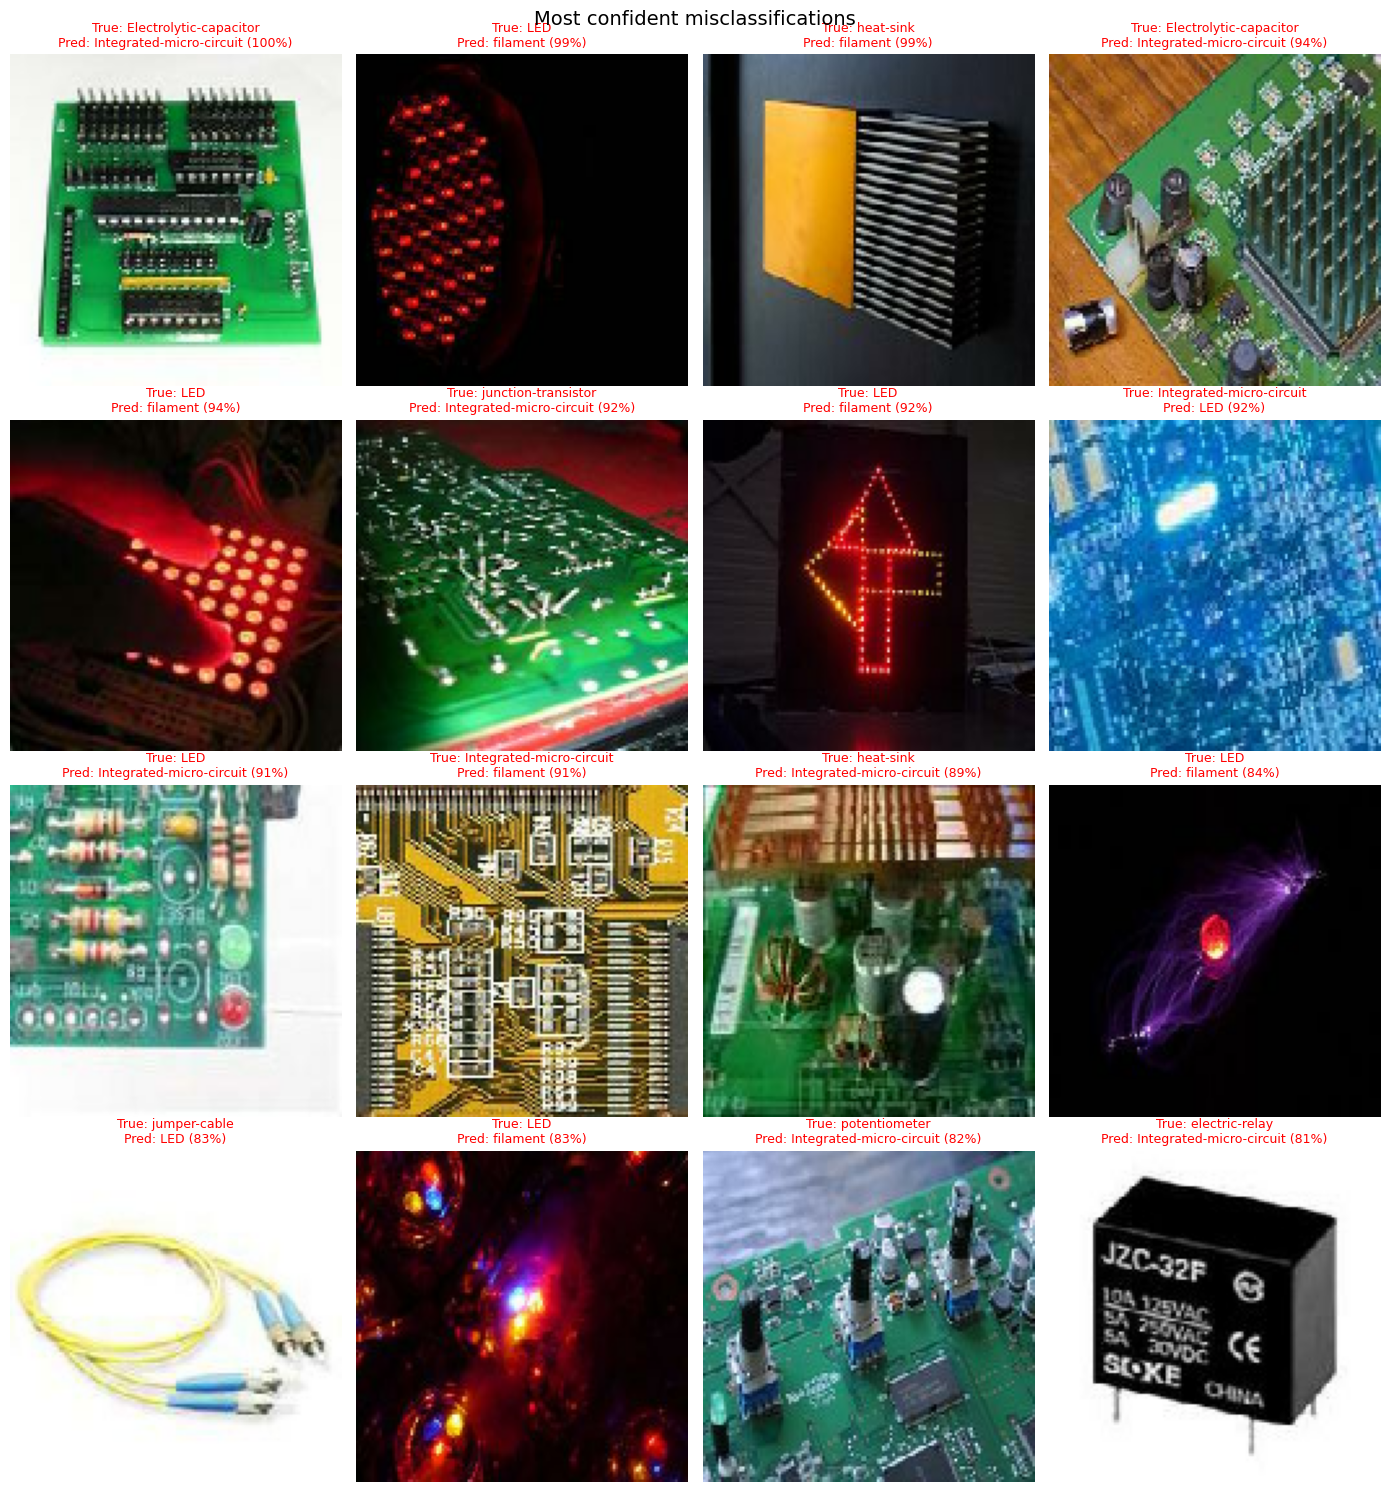

In [11]:
visualize_misclassifications(model, val_ds, class_names, n=16)

#Bonus: Seeing Correct Predictions

In [12]:
import numpy as np
import matplotlib.pyplot as plt


def visualize_correct_classifications(model, val_ds, class_names, n=16, cols=4,
                                      most_confident=True):
    """Display validation images the model classified correctly.

    Args:
        model          : trained model
        val_ds         : validation dataset from data_loader()
        class_names    : list of class names
        n              : how many correctly classified images to show
        cols           : images per row
        most_confident : True = show the predictions the model was MOST sure about;
                         False = show the LEAST confident correct ones (lucky calls)
    """
    right_imgs, right_label, right_conf = [], [], []
    per_class_total = np.zeros(len(class_names), dtype=int)
    per_class_right = np.zeros(len(class_names), dtype=int)

    # Predict batch by batch so each image stays paired with its label
    for images, labels in val_ds:
        probs = model.predict(images, verbose=0)
        preds = np.argmax(probs, axis=1)
        labels = labels.numpy()

        per_class_total += np.bincount(labels, minlength=len(class_names))
        mask = preds == labels
        per_class_right += np.bincount(labels[mask], minlength=len(class_names))

        right_imgs.extend(images.numpy()[mask])
        right_label.extend(labels[mask])
        right_conf.extend(probs[mask, preds[mask]])

    total = per_class_total.sum()
    n_right = len(right_label)
    print(f"Correctly classified {n_right} of {total} validation images "
          f"({n_right / total:.1%})")
    if n_right == 0:
        return

    # Classes the model gets right most often
    recall = per_class_right / np.maximum(per_class_total, 1)
    print("\nBest-recognized classes (correct / total):")
    for c in np.argsort(recall)[::-1][:5]:
        print(f"  {class_names[c]:<25s} {per_class_right[c]:>3d} / {per_class_total[c]:<3d}"
              f" ({recall[c]:.0%})")

    # Choose which correct predictions to show
    order = np.argsort(right_conf)
    order = (order[::-1] if most_confident else order)[:n]

    rows = int(np.ceil(len(order) / cols))
    plt.figure(figsize=(cols * 3.5, rows * 3.8))
    for i, idx in enumerate(order):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(right_imgs[idx])            # already scaled to [0, 1]
        plt.title(f"{class_names[right_label[idx]]}\n"
                  f"Confidence: {right_conf[idx]:.0%}",
                  fontsize=9, color="green")
        plt.axis("off")
    title = ("Most confident correct predictions" if most_confident
             else "Least confident correct predictions")
    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

Correctly classified 389 of 950 validation images (40.9%)

Best-recognized classes (correct / total):
  filament                   65 / 85  (76%)
  jumper-cable               39 / 58  (67%)
  Integrated-micro-circuit   54 / 90  (60%)
  heat-sink                  51 / 87  (59%)
  LED                        50 / 90  (56%)


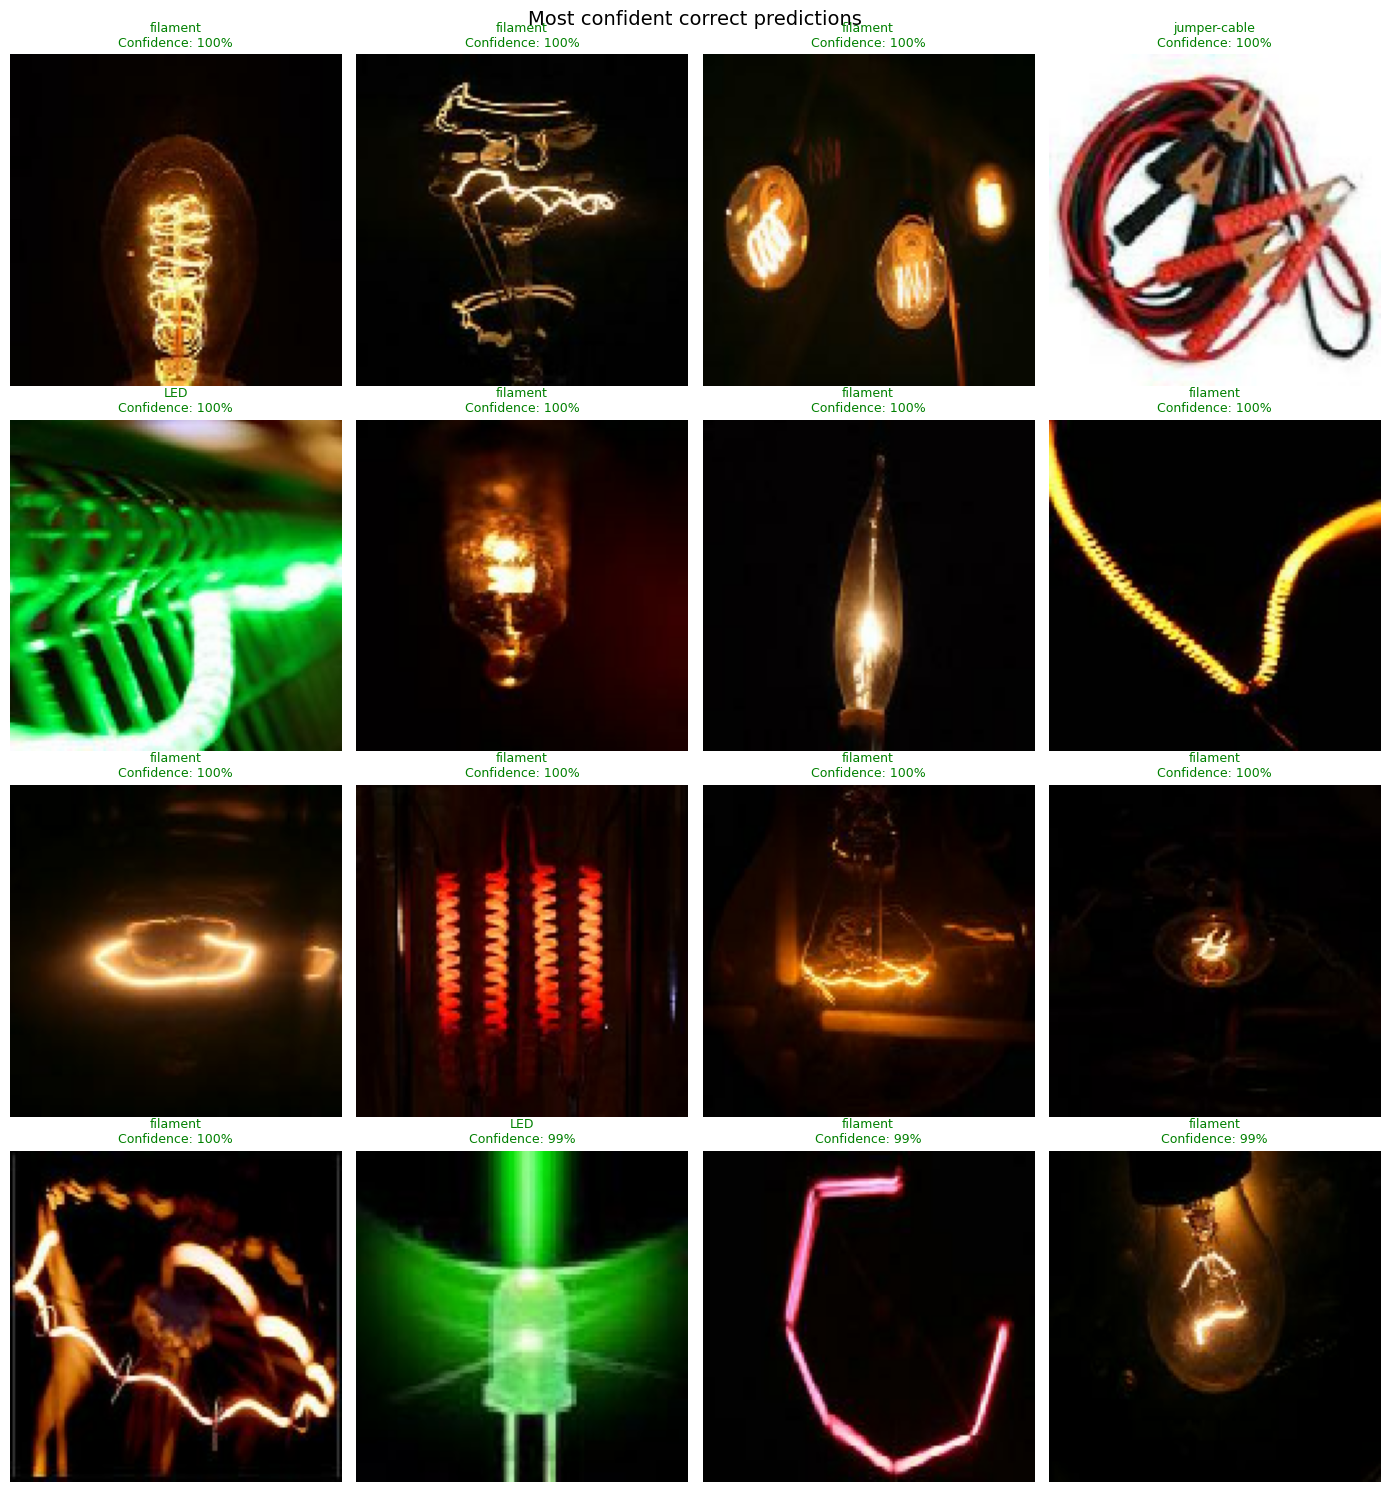

In [13]:
visualize_correct_classifications(model, val_ds, class_names, n=16)